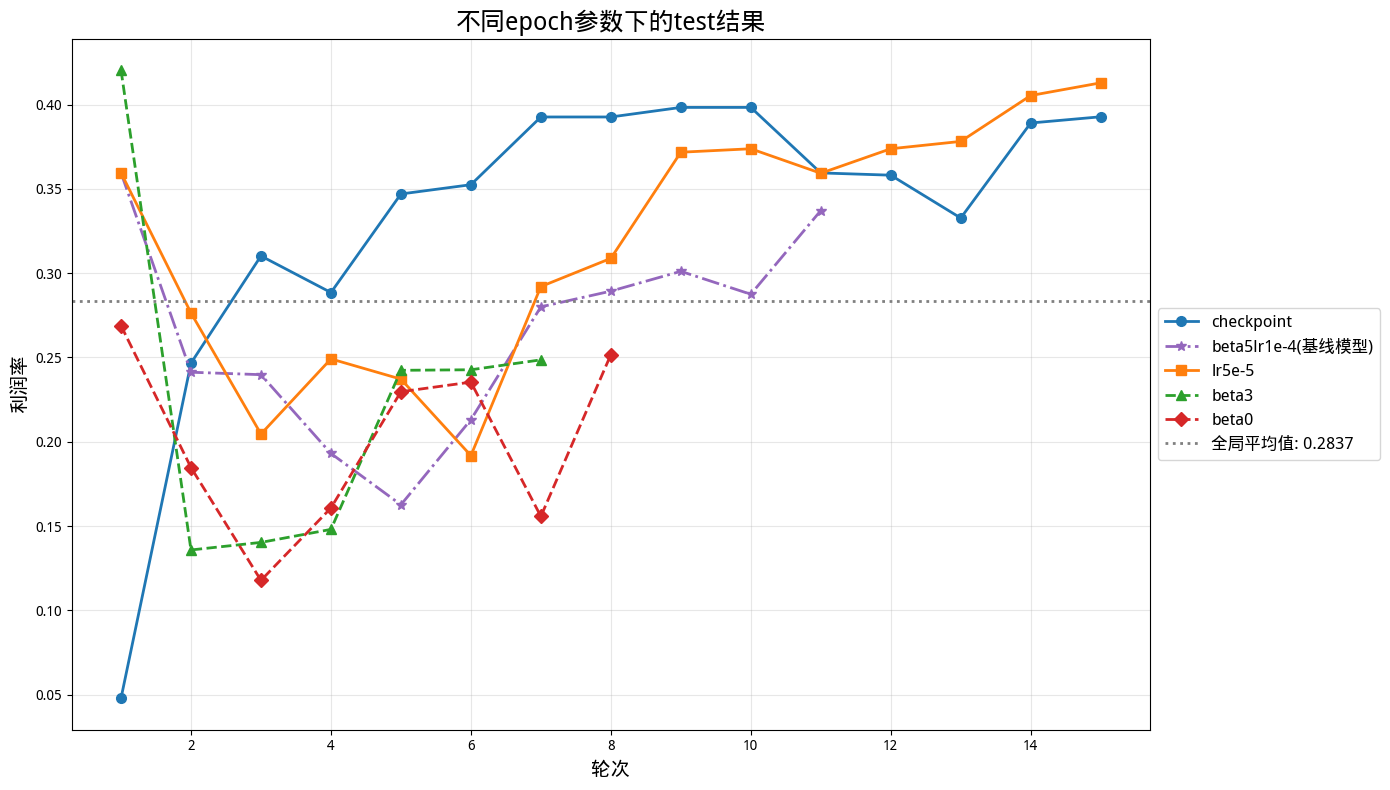

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
from matplotlib import font_manager

# 自动选择可用的中文字体，避免 SimHei 缺失与中文字符警告
def _use_chinese_font():
    candidates = [
        'SimHei', 'Noto Sans CJK SC', 'Noto Sans SC', 'Source Han Sans SC',
        'WenQuanYi Micro Hei', 'WenQuanYi Zen Hei', 'Microsoft YaHei',
        'Arial Unicode MS', 'STHeiti'
    ]
    available = {f.name for f in font_manager.fontManager.ttflist}
    for name in candidates:
        if name in available:
            mpl.rcParams['font.sans-serif'] = [name]
            mpl.rcParams['axes.unicode_minus'] = False
            return name
    # 如果没有找到中文字体，退回默认并提示
    mpl.rcParams['axes.unicode_minus'] = False
    print('未检测到可用中文字体，请安装如 Noto Sans CJK SC 或 WenQuanYi Micro Hei。')
    return None

_font = _use_chinese_font()

# 整理所有数据集
datasets = {
    'checkpoint': [
        0.04779317343110361, 0.24664948821904317, 0.31024833574032523,
        0.2885363575611578, 0.34700726397991044, 0.3525133350247891,
        0.39269369382785557, 0.39269369382785557, 0.39837167353726366,
        0.39837167353726366, 0.3595074331690643, 0.35816069358273683,
        0.3327424410083981, 0.38912249264781706, 0.39280827345683533
    ],
    'beta5lr1e-4(基线模型)': [
        0.3595593596418099, 0.24125538720963802, 0.2398058847183034,
        0.19306993404649658, 0.16261997864255337, 0.21311159478815955,
        0.2800403348047055, 0.28936882288549554, 0.301121074096128,
        0.2875249215719956, 0.33716537665343743
    ],
    'lr5e-5': [
        0.3595593596418099, 0.2763971701623523, 0.20458262707358013,
        0.24916134410101431, 0.2371582699529485, 0.19178215199828946,
        0.29207870409602193, 0.3088117747108463, 0.37178044171704816,
        0.37383992627793217, 0.3593033908564525, 0.37383992627793217,
        0.3781963905746389, 0.4054200105395498, 0.41294717811931103
    ],
    'beta3': [
        0.42050349191774333, 0.13580868669271012, 0.14029220633962242,
        0.14800787473576799, 0.24239514240707566, 0.24271701251525996,
        0.24860228270387258
    ],
    'beta0': [
        0.26887458868447156, 0.1847004374870794, 0.11775946696410731,
        0.1607283237560429, 0.2296884458031757, 0.2353907374103701,
        0.1557079738607609, 0.25168217786167263
    ]
    
}

fig, ax = plt.subplots(figsize=(14, 8))

# 定义颜色和标记（区分不同数据集）
styles = {
    'checkpoint': {'color': '#1f77b4', 'marker': 'o', 'linestyle': '-'},
    'beta5lr1e-4(基线模型)': {'color': '#9467bd', 'marker': '*', 'linestyle': '-.'},
    'lr5e-5': {'color': '#ff7f0e', 'marker': 's', 'linestyle': '-'},
    'beta3': {'color': '#2ca02c', 'marker': '^', 'linestyle': '--'},
    'beta0': {'color': '#d62728', 'marker': 'D', 'linestyle': '--'}
    
}

# 绘制每个数据集的折线图
for name, data in datasets.items():
    x = np.arange(1, len(data)+1)  # 每个数据集的x轴序号（从1开始）
    ax.plot(x, data, label=name, color=styles[name]['color'],
            marker=styles[name]['marker'], markersize=7, linewidth=2,
            linestyle=styles[name]['linestyle'])

# 添加全局平均值参考线（所有数据的平均）
all_data = [val for sublist in datasets.values() for val in sublist]
global_mean = np.mean(all_data)
ax.axhline(y=global_mean, color='gray', linestyle=':', linewidth=2,
           label=f'全局平均值: {global_mean:.4f}')

# 设置图表标题和标签
ax.set_title('不同epoch参数下的test结果', fontsize=18, fontweight='bold')
ax.set_xlabel('轮次', fontsize=14)
ax.set_ylabel('利润率', fontsize=14)

# 设置网格（增强可读性）
ax.grid(True, alpha=0.3)

# 添加图例（位置调整为右侧）
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=12)

# 调整布局（避免图例遮挡）
plt.tight_layout()

# 保存图片
# plt.savefig('all_datasets_profit_margin_comparison.png', dpi=300, bbox_inches='tight')

# 显示图表
plt.show()

[已加载] action: 形状 (1, 219959), 展平后长度 219959
[已加载] commission_fee_history: 形状 (1,), 展平后长度 1
[已加载] final_balance: 形状 (1,), 展平后长度 1
[已加载] require_money: 形状 (1,), 展平后长度 1
[已加载] reward: 形状 (1, 219959), 展平后长度 219959

以下数据仅一个点，直接打印数值：
- commission_fee_history: 值=2.5483108 (原始形状=(1,))
- final_balance: 值=149.50768920000024 (原始形状=(1,))
- require_money: 值=362.05039560000006 (原始形状=(1,))


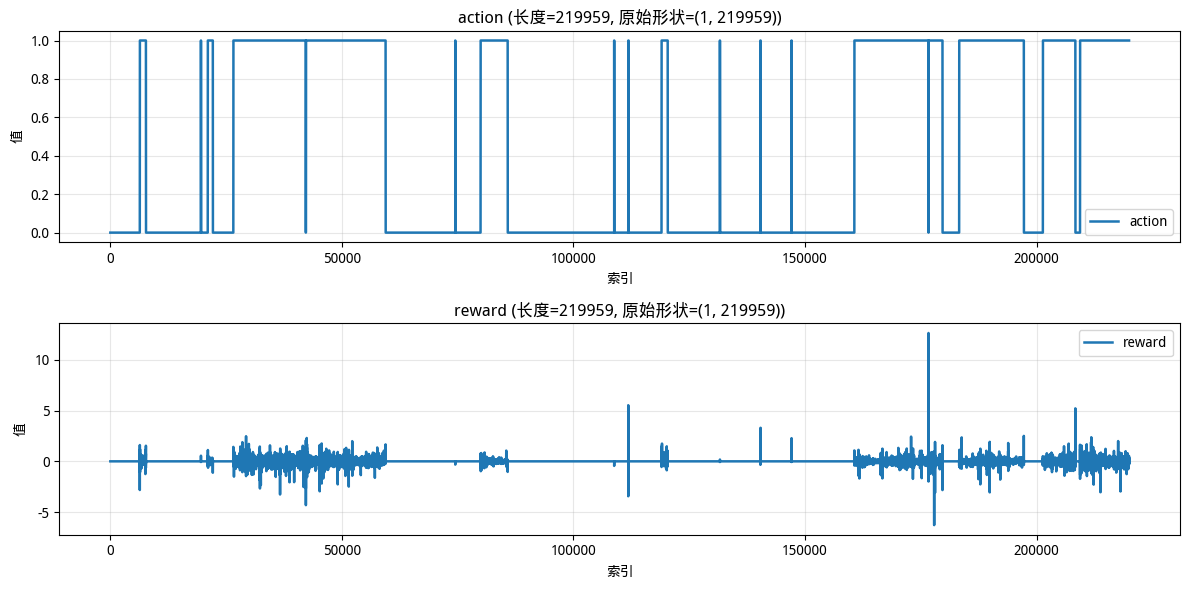

In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt

# 要可视化的 .npy 文件（绝对路径）
base_dir = '/home/ustc1958/lxy/testvalue/reward1000lr5e-5epo15'
files = {
    'action': os.path.join(base_dir, 'action.npy'),
    'commission_fee_history': os.path.join(base_dir, 'commission_fee_history.npy'),
    'final_balance': os.path.join(base_dir, 'final_balance.npy'),
    'require_money': os.path.join(base_dir, 'require_money.npy'),
    'reward': os.path.join(base_dir, 'reward.npy'),
}

loaded = {}
for name, path in files.items():
    if not os.path.exists(path):
        print(f'[跳过] 文件不存在: {path}')
        continue
    try:
        arr = np.load(path, allow_pickle=True)
        # 统一转为一维以便绘图（保留原始形状用于提示）
        orig_shape = arr.shape
        arr_flat = np.asarray(arr).reshape(-1)
        loaded[name] = (arr_flat, orig_shape)
        print(f'[已加载] {name}: 形状 {orig_shape}, 展平后长度 {arr_flat.size}')
    except Exception as e:
        print(f'[错误] 加载 {path} 失败: {e}')

# 将仅一个点的数据直接打印，其余绘制折线图
single_series = {k: v for k, v in loaded.items() if v[0].size <= 1}
series = {k: v for k, v in loaded.items() if v[0].size > 1}

# 直接打印仅一个点的数据
if single_series:
    print('\n以下数据仅一个点，直接打印数值：')
    for name, (arr_flat, orig_shape) in single_series.items():
        val = arr_flat[0] if arr_flat.size == 1 else arr_flat
        print(f'- {name}: 值={val} (原始形状={orig_shape})')

# 绘制多点数据
if series:
    n = len(series)
    fig, axes = plt.subplots(nrows=n, ncols=1, figsize=(12, max(3*n, 4)), sharex=False)
    if n == 1:
        axes = [axes]
    for ax, (name, (arr_flat, orig_shape)) in zip(axes, series.items()):
        x = np.arange(len(arr_flat))
        ax.plot(x, arr_flat, label=f'{name}', color='#1f77b4', linewidth=1.8)
        ax.set_title(f'{name} (长度={arr_flat.size}, 原始形状={orig_shape})')
        ax.set_xlabel('索引')
        ax.set_ylabel('值')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='best')
    plt.tight_layout()
    plt.show()
else:
    print('无可绘制的多点数据。')

In [18]:
import os
import numpy as np

# 数据目录：默认复用上文 base_dir，如无则请手动修改为实际目录
data_dir1 = globals().get('base_dir', '/home/ustc1958/lxy/testvalue/reward1000lr5e-5epo15')

# 年化因子：分钟频 525600，如为秒/小时/天请相应调整
m = 525600

# 鲁棒读取 require_money 与 reward
def _load_scalar(path):
    arr = np.load(path, allow_pickle=True)
    arr = np.asarray(arr).reshape(-1)
    if arr.size == 0:
        raise ValueError(f'空数组: {path}')
    return float(arr[0])

try:
    V_1 = _load_scalar(os.path.join(data_dir1, 'require_money.npy'))
except Exception as e:
    print(f'[错误] 加载 require_money.npy 失败: {e}')
    raise

try:
    reward = np.load(os.path.join(data_dir1, 'reward.npy'), allow_pickle=True)
    reward = np.asarray(reward, dtype=float).reshape(-1)
except Exception as e:
    print(f'[错误] 加载 reward.npy 失败: {e}')
    raise

# 用 reward 与初始资金还原净值曲线
net_value = V_1 + np.cumsum(reward)
V_T = float(net_value[-1])

# 每步收益率 r = Δ净值 / 上期净值（加入除零保护）
EPS = 1e-12
den = np.where(np.abs(net_value[:-1]) < EPS, np.sign(net_value[:-1]) * EPS, net_value[:-1])
r = np.diff(net_value) / den

# 1) 总回报率 TR（%）
TR = (V_T - V_1) / max(abs(V_1), EPS) * 100.0

# 2) 年度波动率 AVOL（%）
AVOL = float(np.std(r)) * np.sqrt(m) * 100.0 if r.size > 0 else np.nan

# 3) 最大回撤 MDD（%）
peak = np.maximum.accumulate(net_value)
drawdown = np.where(peak == 0, 0.0, (peak - net_value) / peak)
MDD = float(np.max(drawdown)) * 100.0 if drawdown.size > 0 else np.nan

# 4) 年化夏普比率 ASR（rf=0）
mu = float(np.mean(r)) if r.size > 0 else 0.0
sigma = float(np.std(r)) if r.size > 0 else 0.0
ASR = (mu / sigma) * np.sqrt(m) if sigma > 0 else np.nan

# 5) 年化卡玛比率 ACR
ACR = (mu * m) / (MDD / 100.0) if (MDD is not np.nan and MDD > 0) else np.nan

# 6) 年度索提诺比率 ASoR
downside = r[r < 0]
DD = float(np.std(downside)) if downside.size > 0 else 0.0
ASoR = (mu / DD) * np.sqrt(m) if DD > 0 else np.nan

print(f'基于目录: {data_dir1}')
print(f'Total Return (TR): {TR:.2f}%')
print(f'Annual Volatility (AVOL): {AVOL:.2f}%')
print(f'Maximum Drawdown (MDD): {MDD:.2f}%')
print(f'Annual Sharpe Ratio (ASR): {ASR:.2f}')
print(f'Annual Calmar Ratio (ACR): {ACR:.2f}')
print(f'Annual Sortino Ratio (ASoR): {ASoR:.2f}')

基于目录: /home/ustc1958/lxy/testvalue/reward1000lr5e-5epo15
Total Return (TR): 41.29%
Annual Volatility (AVOL): 20.77%
Maximum Drawdown (MDD): 8.40%
Annual Sharpe Ratio (ASR): 4.08
Annual Calmar Ratio (ACR): 10.10
Annual Sortino Ratio (ASoR): 3.27


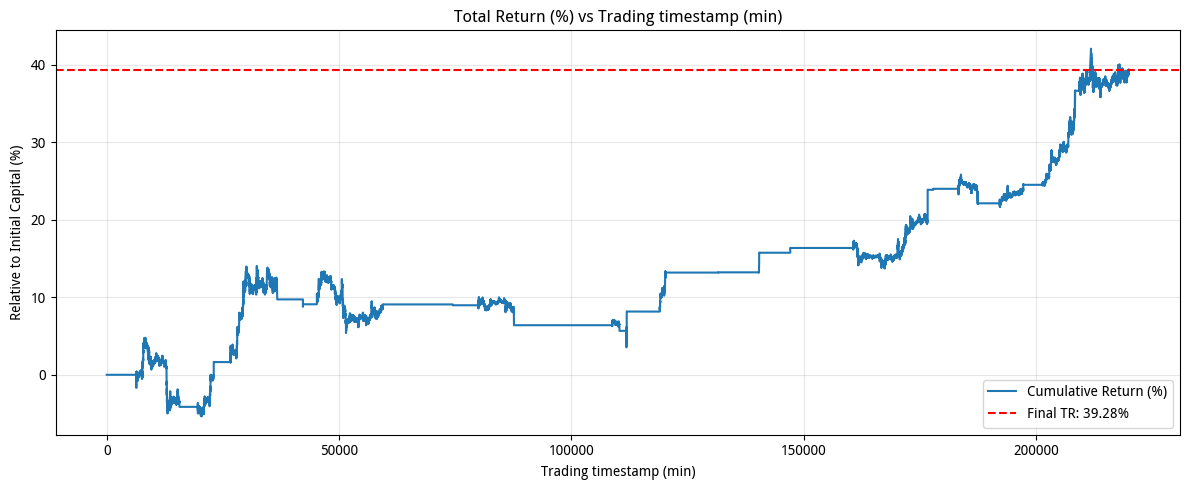

基于目录: /home/ustc1958/lxy/testvalue/yuan
Final TR: 39.28%


In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt

# 选择数据目录：优先 data_dir1，其次 base_dir，最后默认值
_data_dir = (
    # globals().get('data_dir1')
    # or globals().get('base_dir')
    '/home/ustc1958/lxy/testvalue/yuan'
)

# 加载初始资金与 reward
def _load_scalar_first(path):
    arr = np.load(path, allow_pickle=True)
    arr = np.asarray(arr).reshape(-1)
    if arr.size == 0:
        raise ValueError(f'空数组: {path}')
    return float(arr[0])

V_1 = _load_scalar_first(os.path.join(_data_dir, 'require_money.npy'))
reward = np.load(os.path.join(_data_dir, 'reward.npy'), allow_pickle=True)
reward = np.asarray(reward, dtype=float).flatten()

# 可视化累计收益率（资金曲线），y 轴为相对初始资金的百分比
cum_return = np.cumsum(reward) / V_1 * 100.0
final_tr = float(cum_return[-1]) if cum_return.size else np.nan

timestamps = np.arange(cum_return.size)
plt.figure(figsize=(12, 5))
plt.plot(timestamps, cum_return, label='Cumulative Return (%)')
if np.isfinite(final_tr):
    plt.axhline(final_tr, color='r', linestyle='--', label=f'Final TR: {final_tr:.2f}%')

plt.title('Total Return (%) vs Trading timestamp (min)')
plt.xlabel('Trading timestamp (min)')
plt.ylabel('Relative to Initial Capital (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'基于目录: {_data_dir}')
if np.isfinite(final_tr):
    print(f'Final TR: {final_tr:.2f}%')